In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

file_path = 'chronic_kidney_disease_risk_prediction_dataset.csv'
df = pd.read_csv(file_path)

display(df.head())

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Glucose,...,Heart_Disease,Kidney_Stone_History,Medication_Adherence,Work_Type,Residence_Type,Air_Pollution_Exposure,CKD_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,CKD_Risk
0,1,32.0,Male,Singapore,163.7,125.8,46.9,103,103,179.8,...,No,No,Average,Self-Employed,Urban,Low,86,Immediate Medical Attention,Yes,High
1,2,31.0,Male,Brazil,155.6,60.5,25.0,167,76,97.5,...,No,No,Average,Self-Employed,Urban,Medium,70,Immediate Medical Attention,Yes,High
2,3,44.0,Other,India,155.0,88.7,36.9,99,98,158.9,...,No,No,Good,Student,Rural,High,79,Strict Blood Pressure Management,Yes,High
3,4,36.0,Female,France,167.0,55.4,19.9,123,107,144.3,...,No,No,Good,Private,Rural,High,47,Reduce Salt Intake,Yes,Moderate
4,5,NaN,Male,South Africa,NaN,NaN,30.8,123,92,NaN,...,No,No,NaN,Private,Urban,High,92,Consult Nephrologist Immediately,Yes,High


In [2]:
print("\nINFORMASI TIPE DATA & NON-NULL COUNT")
df.info()


INFORMASI TIPE DATA & NON-NULL COUNT
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient_ID                  50000 non-null  int64  
 1   Age                         48901 non-null  float64
 2   Gender                      50000 non-null  str    
 3   Country                     50000 non-null  str    
 4   Height_cm                   47098 non-null  float64
 5   Weight_kg                   46621 non-null  float64
 6   BMI                         50000 non-null  float64
 7   Blood_Pressure_Systolic     50000 non-null  int64  
 8   Blood_Pressure_Diastolic    50000 non-null  int64  
 9   Blood_Glucose               47491 non-null  float64
 10  Serum_Creatinine            47136 non-null  float64
 11  Blood_Urea                  47370 non-null  float64
 12  eGFR                        47369 non-null  float64
 13  Albu

In [3]:
print("\nSTATISTIK DESKRIPTIF DATASET")
display(df.describe(include='all'))


STATISTIK DESKRIPTIF DATASET


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Glucose,...,Heart_Disease,Kidney_Stone_History,Medication_Adherence,Work_Type,Residence_Type,Air_Pollution_Exposure,CKD_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,CKD_Risk
count,50000.000000,48901.000000,50000,50000,47098.000000,46621.000000,50000.000000,50000.000000,50000.000000,47491.000000,...,50000,50000,49246,50000,50000,50000,50000.000000,50000,50000,50000
unique,NaN,NaN,3,25,NaN,NaN,NaN,NaN,NaN,NaN,...,2,2,3,5,2,3,NaN,15,2,3
top,NaN,NaN,Male,Spain,NaN,NaN,NaN,NaN,NaN,NaN,...,No,No,Average,Private,Urban,Medium,NaN,Dialysis Evaluation,Yes,High
freq,NaN,NaN,16692,2071,NaN,NaN,NaN,NaN,NaN,NaN,...,40934,39881,16518,10050,25014,16935,NaN,7852,46965,38823
mean,25000.500000,54.046073,NaN,NaN,169.967941,87.548510,30.832196,134.920400,85.049200,144.648542,...,NaN,NaN,NaN,NaN,NaN,NaN,76.881560,NaN,NaN,NaN
std,14433.901067,21.121412,NaN,NaN,14.435806,24.513469,10.124095,26.192458,14.706758,43.322345,...,NaN,NaN,NaN,NaN,NaN,NaN,15.941806,NaN,NaN,NaN
min,1.000000,18.000000,NaN,NaN,145.000000,45.000000,11.900000,90.000000,60.000000,70.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,9.000000,NaN,NaN,NaN
25%,12500.750000,36.000000,NaN,NaN,157.400000,66.400000,22.800000,112.000000,72.000000,107.200000,...,NaN,NaN,NaN,NaN,NaN,NaN,66.000000,NaN,NaN,NaN
50%,25000.500000,54.000000,NaN,NaN,170.100000,87.600000,30.000000,135.000000,85.000000,144.400000,...,NaN,NaN,NaN,NaN,NaN,NaN,78.000000,NaN,NaN,NaN
75%,37500.250000,72.000000,NaN,NaN,182.400000,108.800000,37.500000,157.000000,98.000000,182.400000,...,NaN,NaN,NaN,NaN,NaN,NaN,90.000000,NaN,NaN,NaN


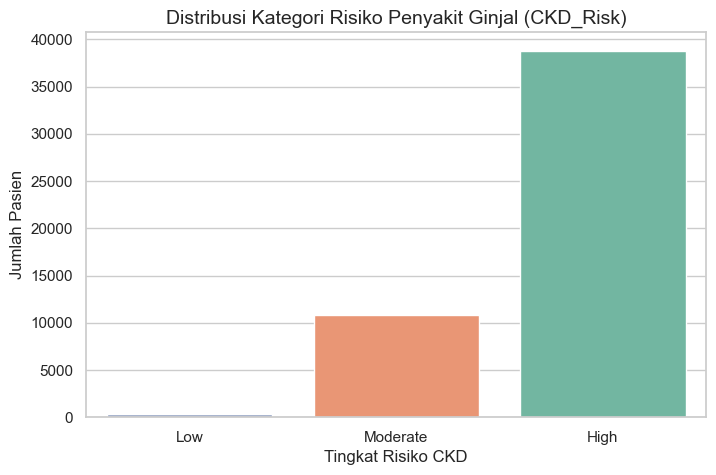

In [4]:
# 1. Memuat dataset ke dalam variabel 'df'
df = pd.read_csv('chronic_kidney_disease_risk_prediction_dataset.csv')

# 2. Kode Visualisasi
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(x='CKD_Risk', hue='CKD_Risk', data=df, palette='Set2', order=['Low', 'Moderate', 'High'], legend=False)
plt.title('Distribusi Kategori Risiko Penyakit Ginjal (CKD_Risk)', fontsize=14)
plt.xlabel('Tingkat Risiko CKD')
plt.ylabel('Jumlah Pasien')
plt.show()

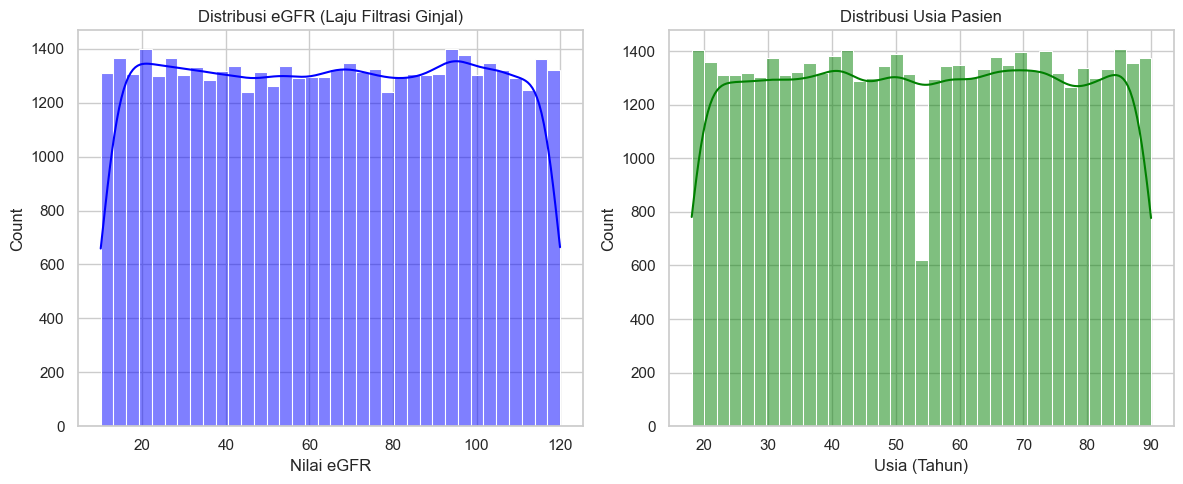

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['eGFR'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribusi eGFR (Laju Filtrasi Ginjal)', fontsize=12)
axes[0].set_xlabel('Nilai eGFR')

sns.histplot(df['Age'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribusi Usia Pasien', fontsize=12)
axes[1].set_xlabel('Usia (Tahun)')

plt.tight_layout()
plt.show()

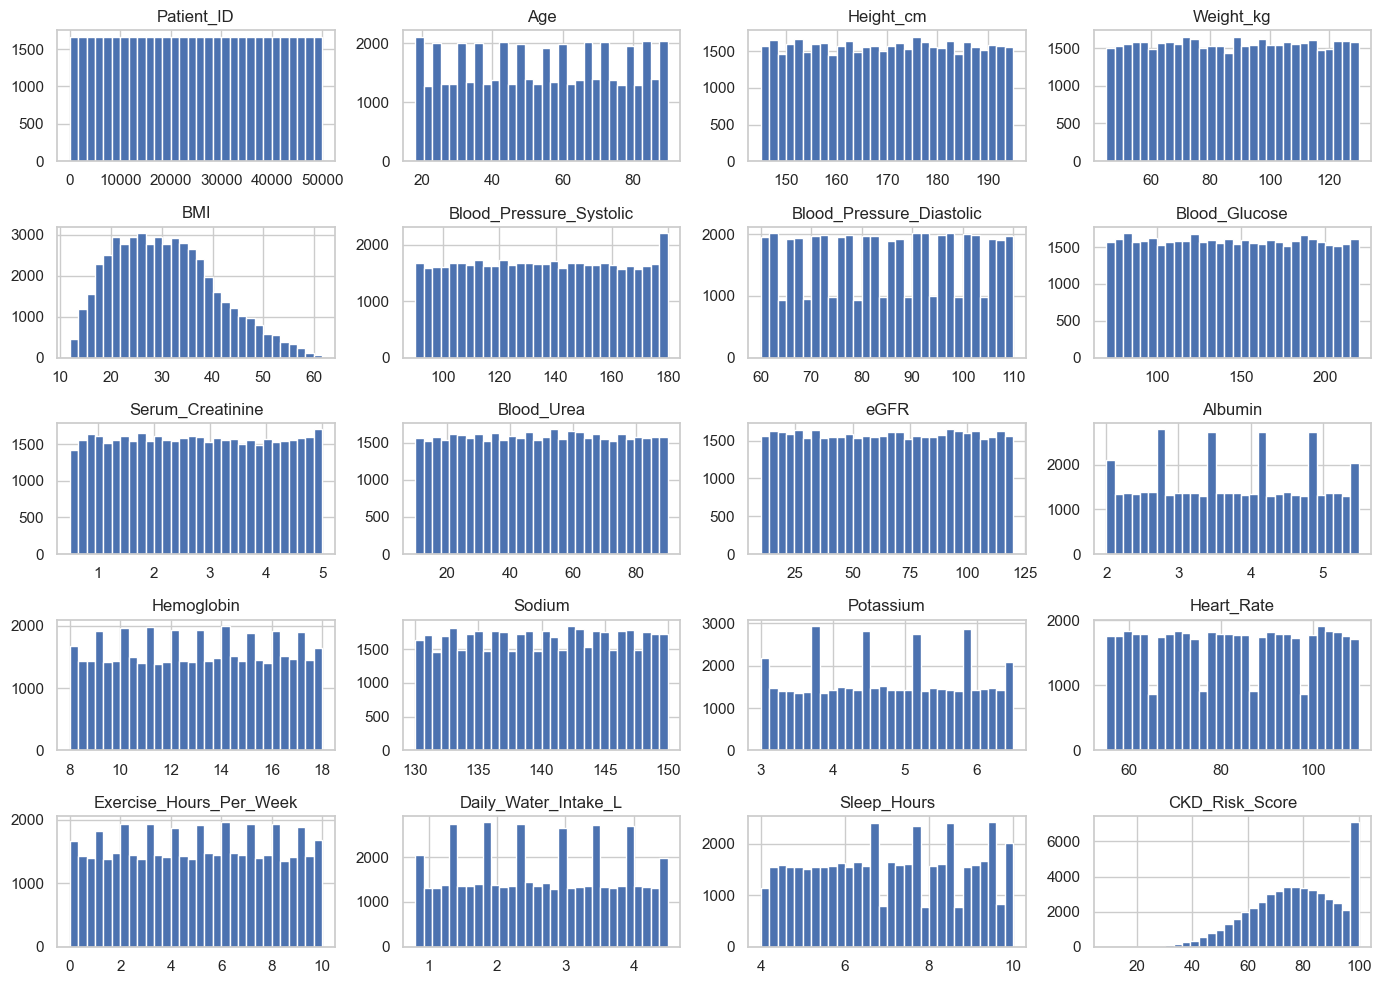

In [6]:
df.hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

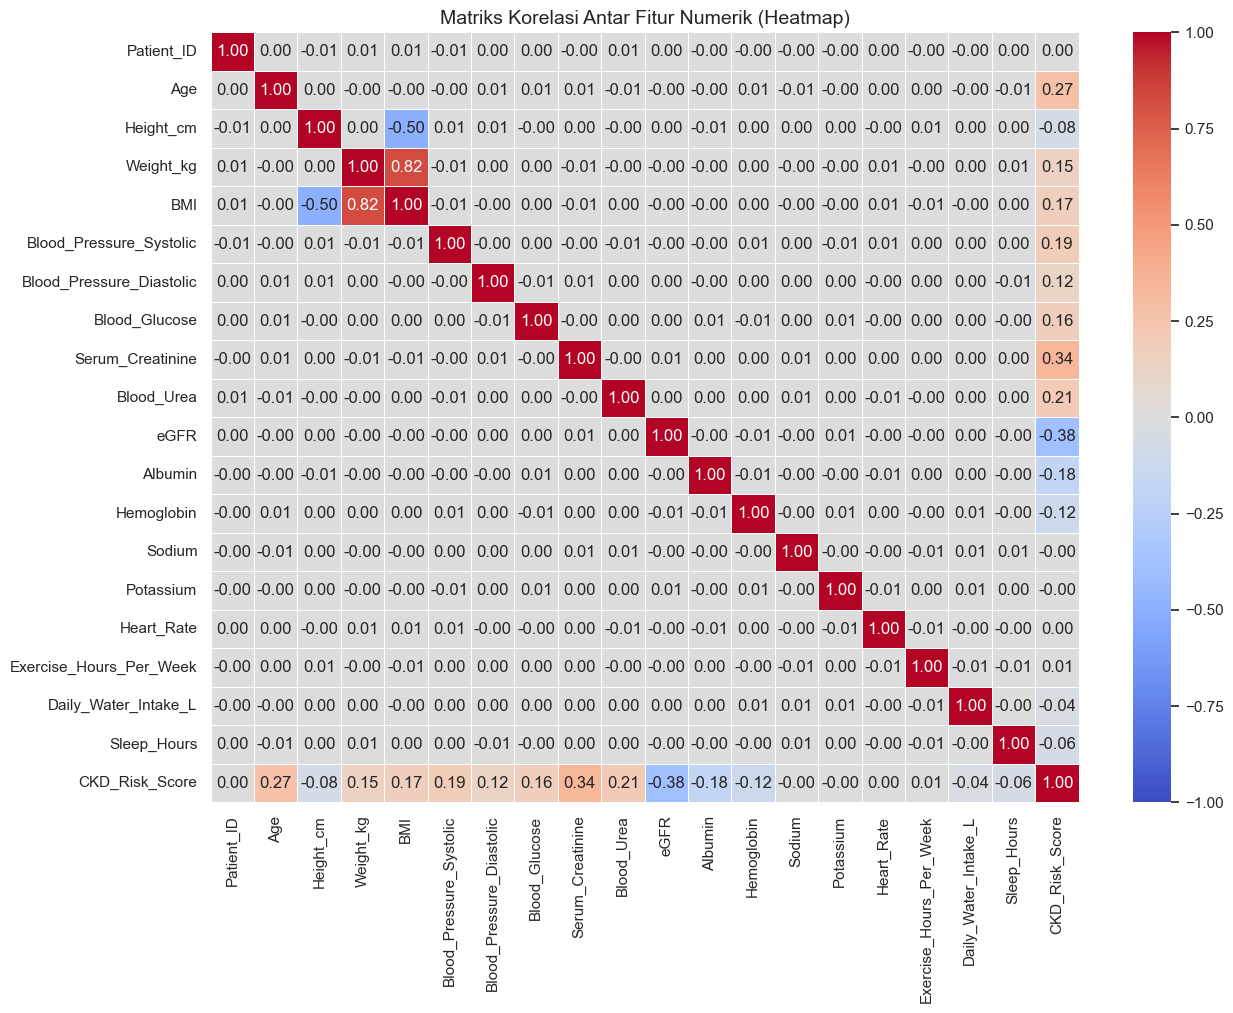

In [7]:
num_cols_for_corr = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(14, 10))
correlation_matrix = df[num_cols_for_corr].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriks Korelasi Antar Fitur Numerik (Heatmap)', fontsize=14)
plt.show()

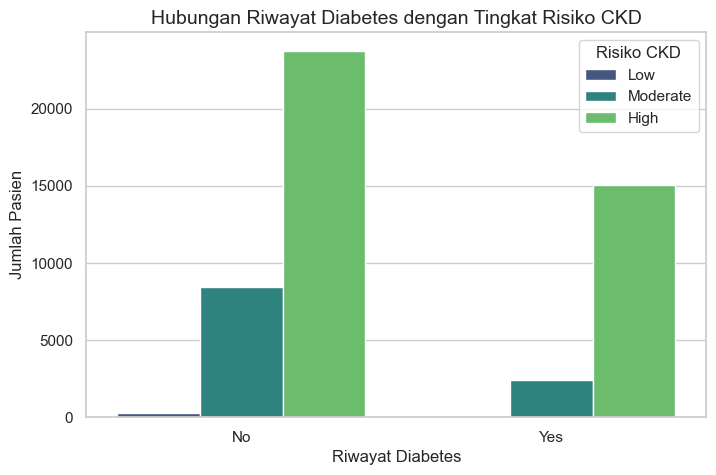

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Diabetes', hue='CKD_Risk', data=df, palette='viridis', hue_order=['Low', 'Moderate', 'High'])
plt.title('Hubungan Riwayat Diabetes dengan Tingkat Risiko CKD', fontsize=14)
plt.xlabel('Riwayat Diabetes')
plt.ylabel('Jumlah Pasien')
plt.legend(title='Risiko CKD')
plt.show()

In [9]:
cols_to_drop = ['Patient_ID', 'CKD_Risk_Score', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed']
cols_to_drop = [col for col in cols_to_drop if col in df.columns]
df_clean = df.drop(columns=cols_to_drop)

print(f"Kolom dibuang: {cols_to_drop}")
print(f"Sisa fitur: {df_clean.shape[1] - 1} kolom")

X = df_clean.drop('CKD_Risk', axis=1)
y = df_clean['CKD_Risk']

Kolom dibuang: ['Patient_ID', 'CKD_Risk_Score', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed']
Sisa fitur: 35 kolom


EDA:ANALISIS



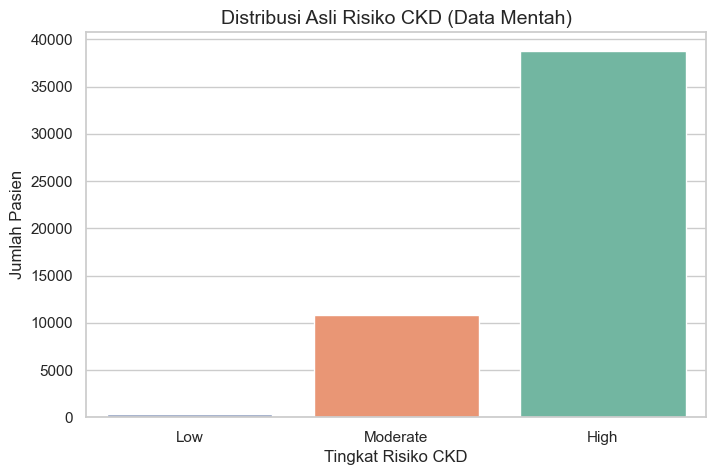

In [10]:
sns.set_theme(style="whitegrid")

print("EDA:ANALISIS\n")

# 1. Distribusi Target Asli
plt.figure(figsize=(8, 5))
sns.countplot(x='CKD_Risk', hue='CKD_Risk', data=df_clean, palette='Set2', order=['Low', 'Moderate', 'High'], legend=False)
plt.title('Distribusi Asli Risiko CKD (Data Mentah)', fontsize=14)
plt.xlabel('Tingkat Risiko CKD')
plt.ylabel('Jumlah Pasien')
plt.show()

In [11]:
# ==============================================================================
# PENANGANAN OUTLIER DENGAN METODE IQR
# ==============================================================================

# 1. Identifikasi kolom numerik
cols_for_iqr = df.select_dtypes(include=['number']).columns.tolist()

print(" STATISTIK SEBELUM PENANGANAN OUTLIER ")
print(f"Jumlah baris awal: {df.shape[0]}")

# 2. Hitung Q1, Q3, dan IQR untuk setiap kolom numerik
Q1 = df[cols_for_iqr].quantile(0.25)
Q3 = df[cols_for_iqr].quantile(0.75)
IQR = Q3 - Q1

# 3. Tentukan batas bawah dan batas atas
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 4. Cek berapa banyak outlier di setiap kolom
print("\n JUMLAH OUTLIER PER KOLOM ")
outlier_counts = {}
for col in cols_for_iqr:
    outliers = ((df[col] < lower_bound[col]) | (df[col] > upper_bound[col])).sum()
    if outliers > 0:
        outlier_counts[col] = outliers
        print(f"  {col}: {outliers} outlier ({outliers/len(df)*100:.1f}%)")

if not outlier_counts:
    print("  Tidak ada outlier yang terdeteksi.")

# 5. Hapus baris yang mengandung outlier di kolom manapun
condition = ~((df[cols_for_iqr] < lower_bound) | (df[cols_for_iqr] > upper_bound)).any(axis=1)
df = df.loc[condition].reset_index(drop=True)

print(f"\n HASIL SETELAH PENANGANAN OUTLIER ")
print(f"Jumlah baris setelah dibersihkan: {df.shape[0]}")
print(f"Jumlah baris yang dibuang: {50000 - df.shape[0]}")

 STATISTIK SEBELUM PENANGANAN OUTLIER 
Jumlah baris awal: 50000

 JUMLAH OUTLIER PER KOLOM 
  BMI: 92 outlier (0.2%)
  CKD_Risk_Score: 132 outlier (0.3%)

 HASIL SETELAH PENANGANAN OUTLIER 
Jumlah baris setelah dibersihkan: 49776
Jumlah baris yang dibuang: 224


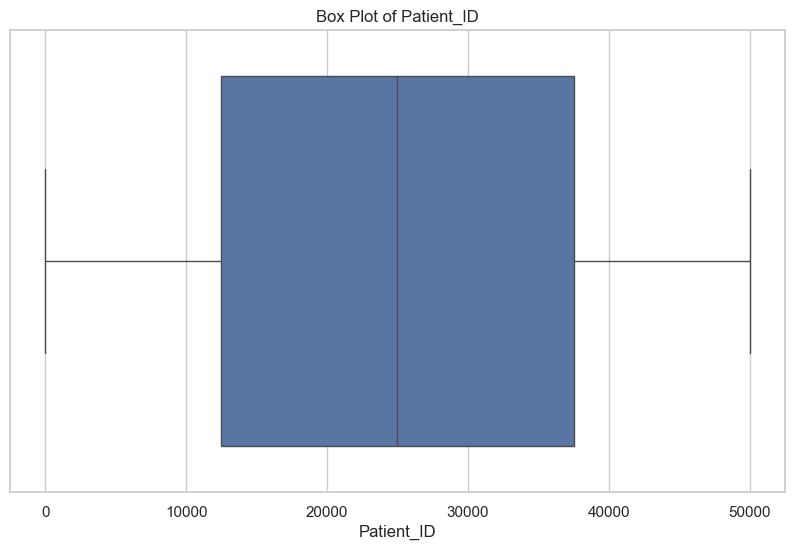

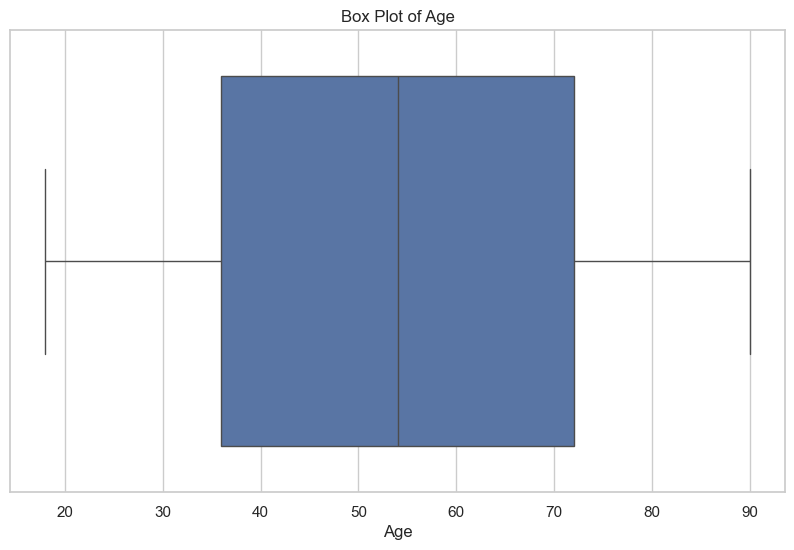

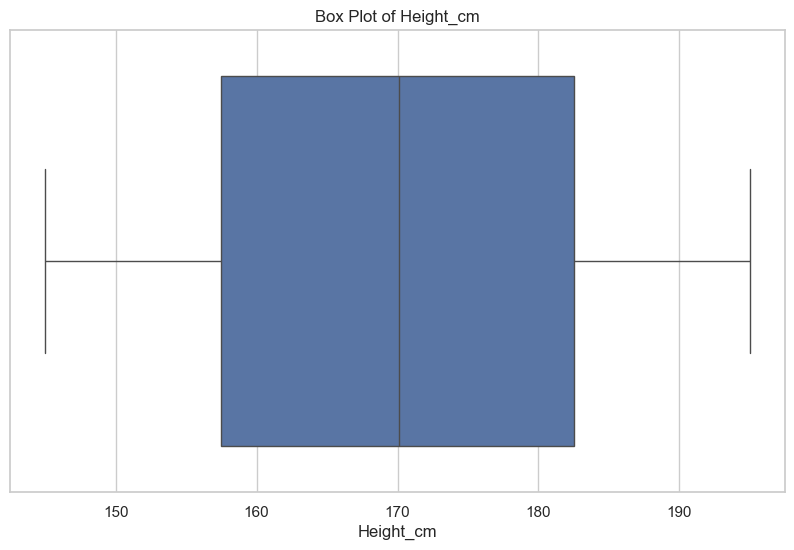

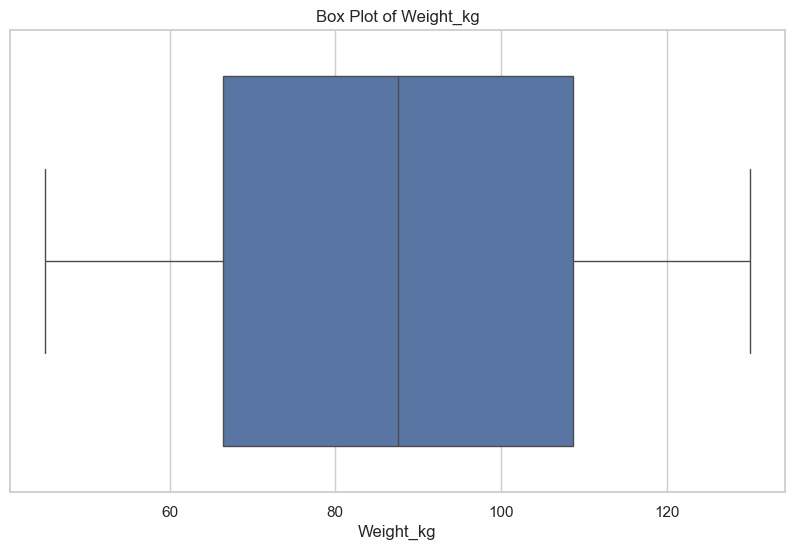

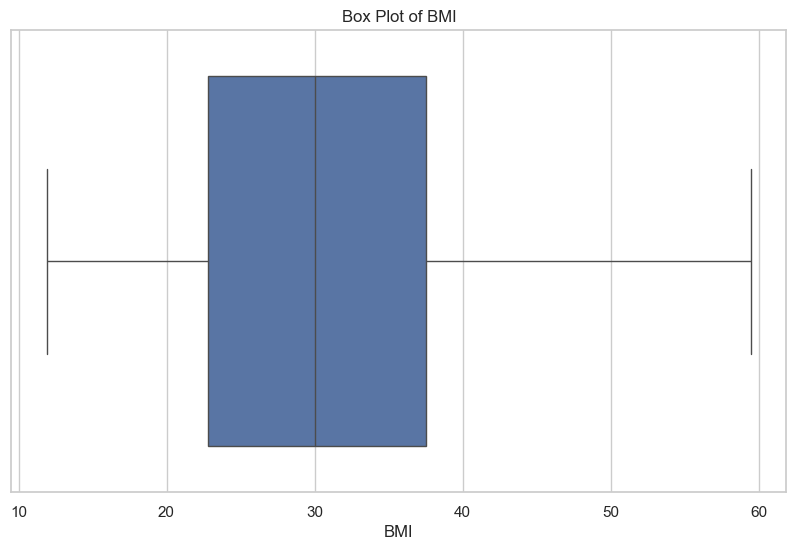

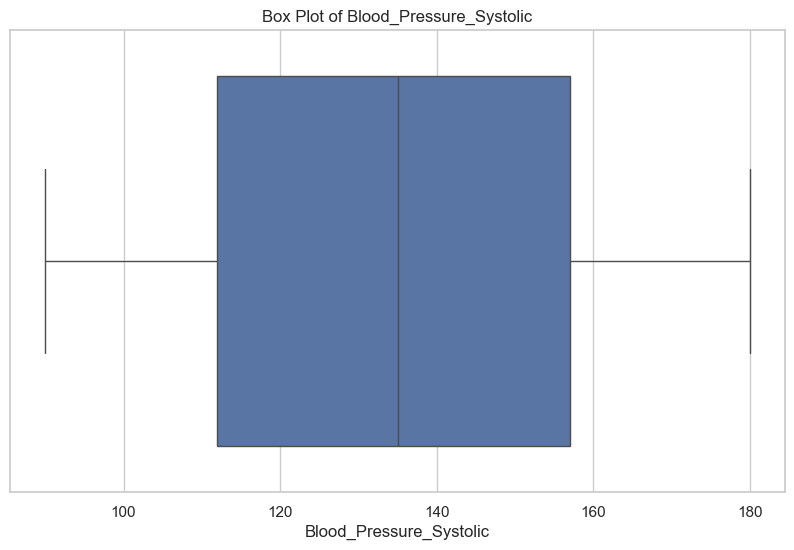

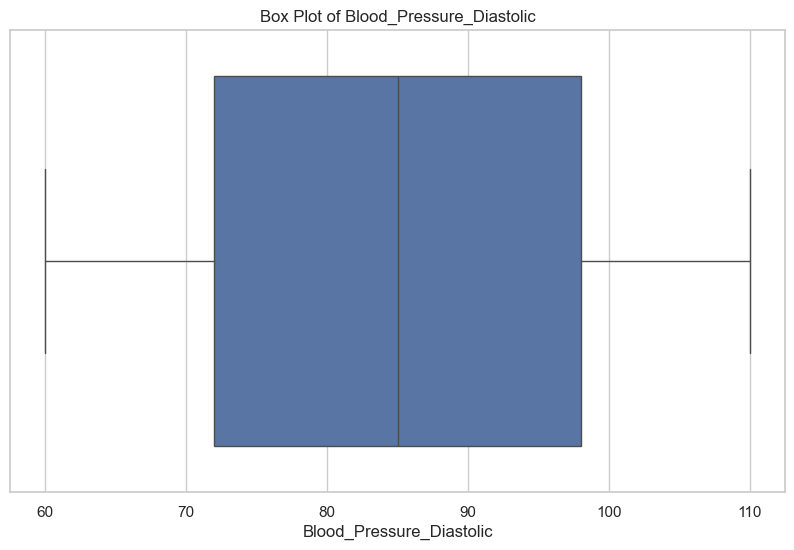

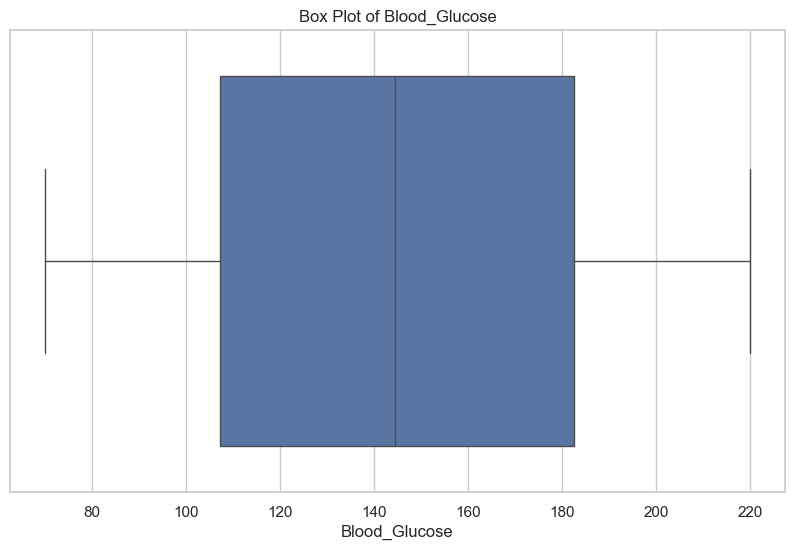

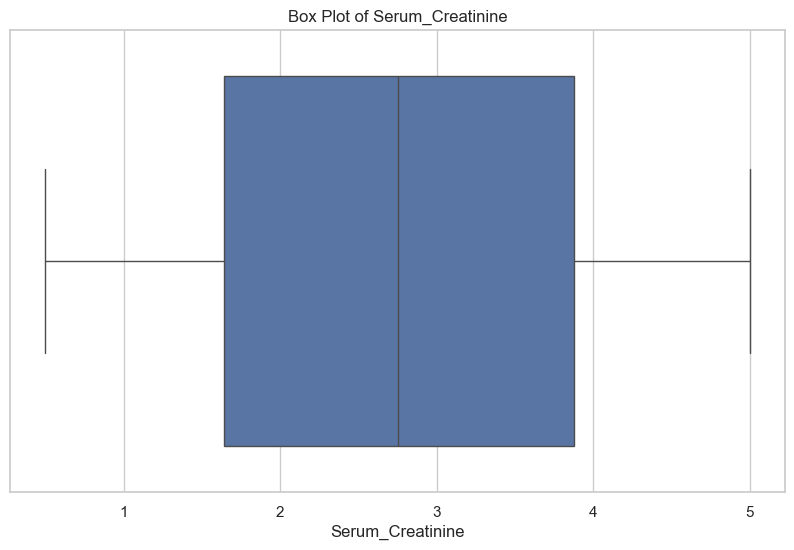

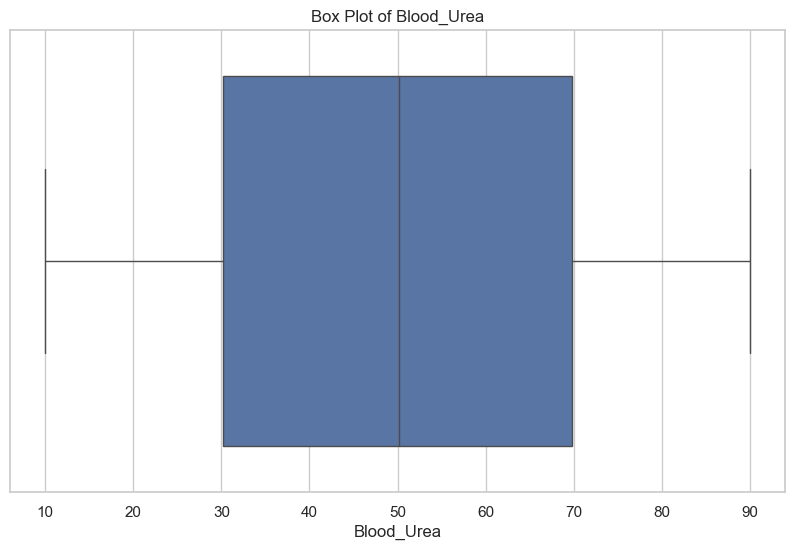

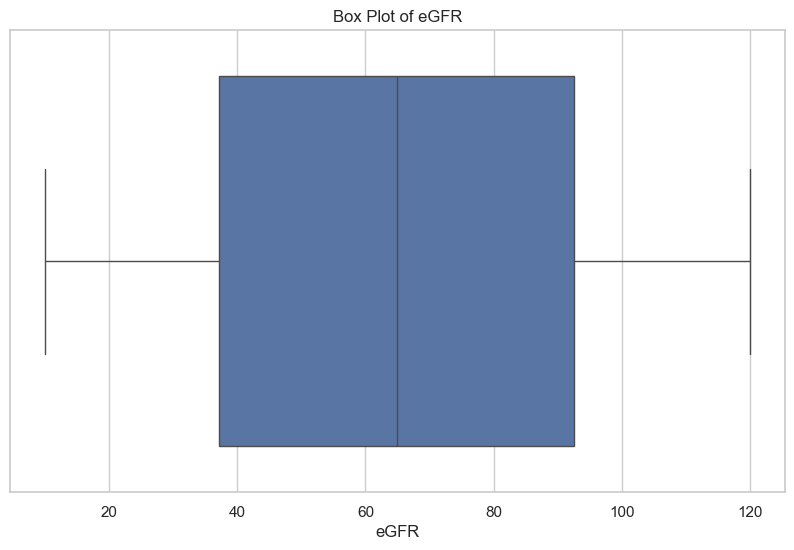

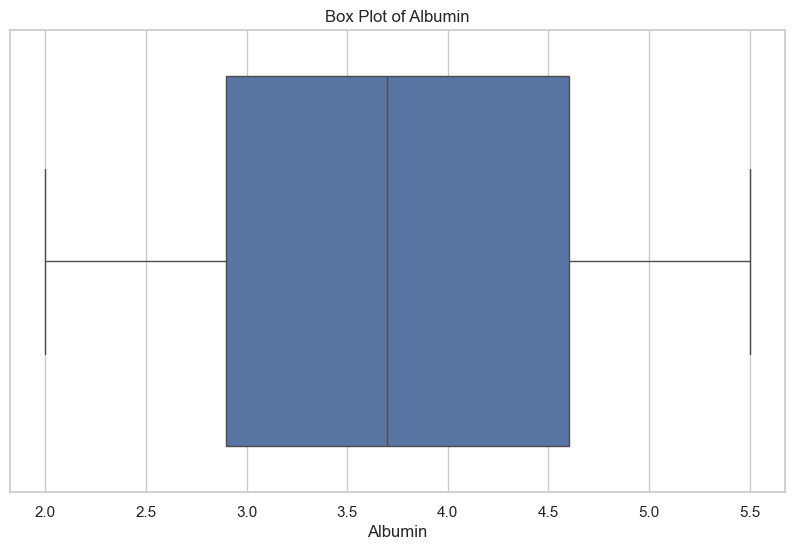

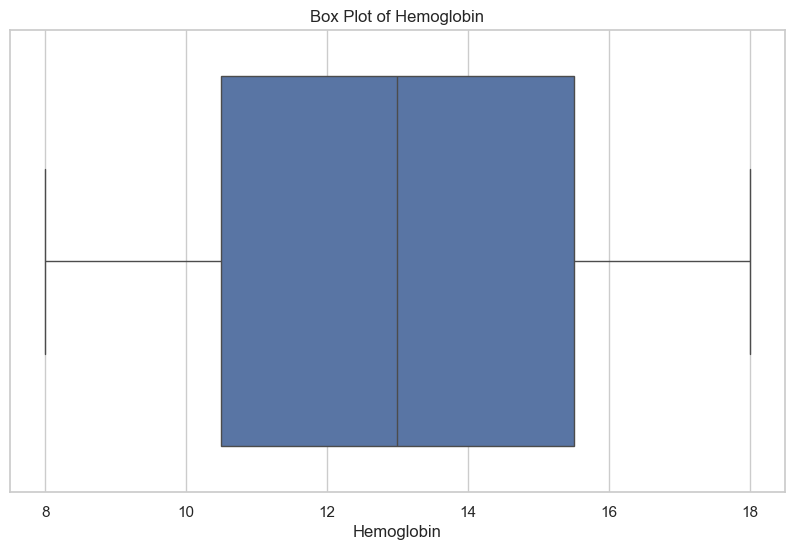

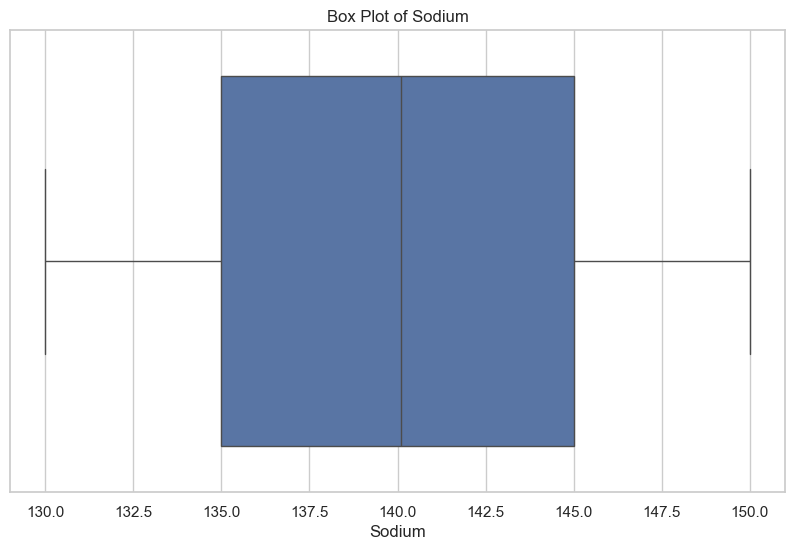

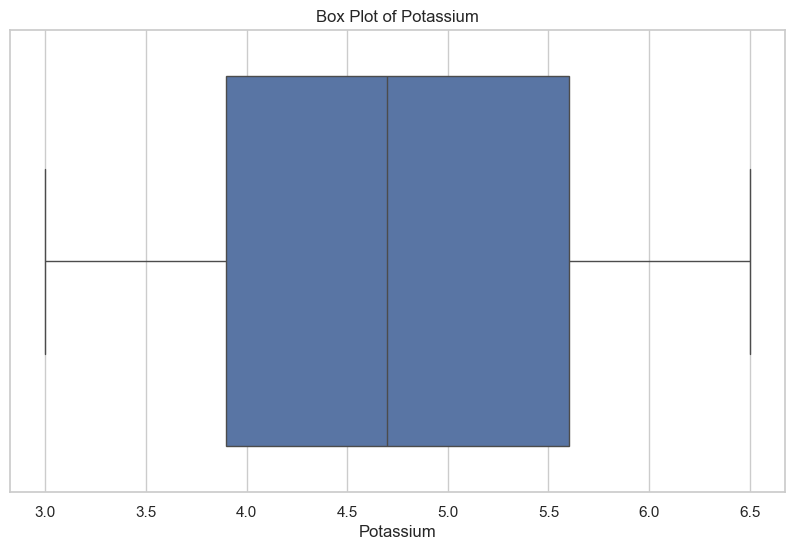

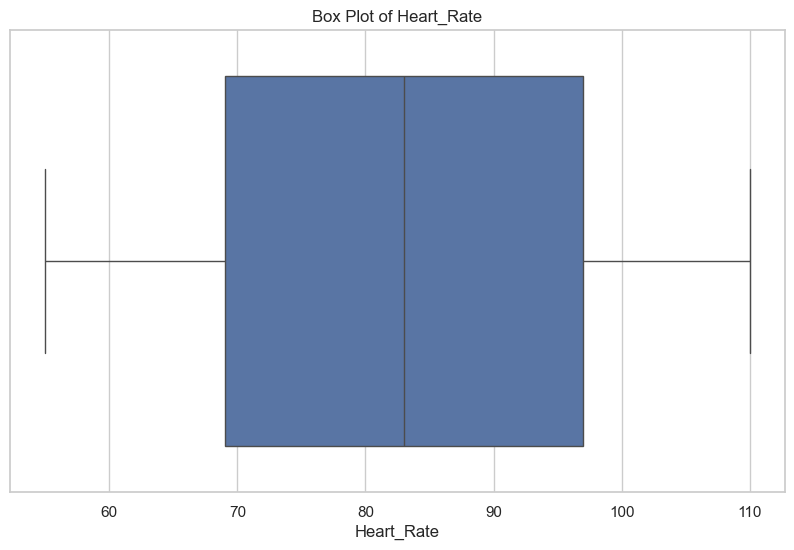

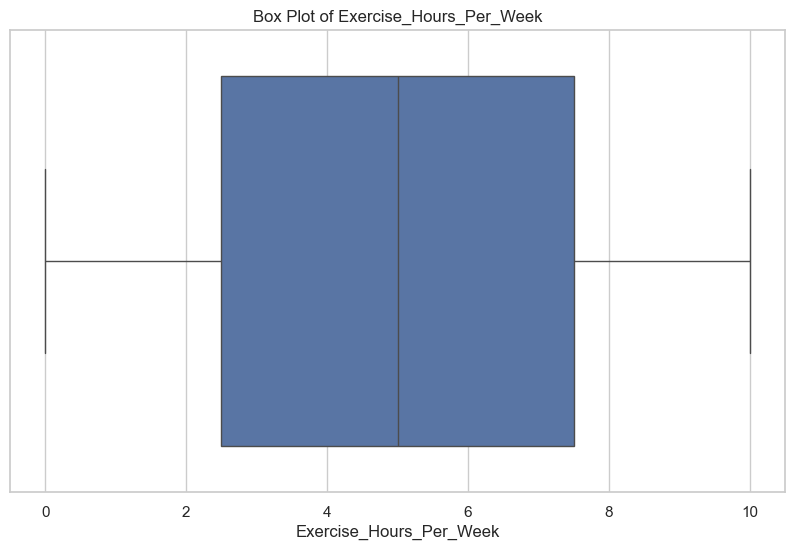

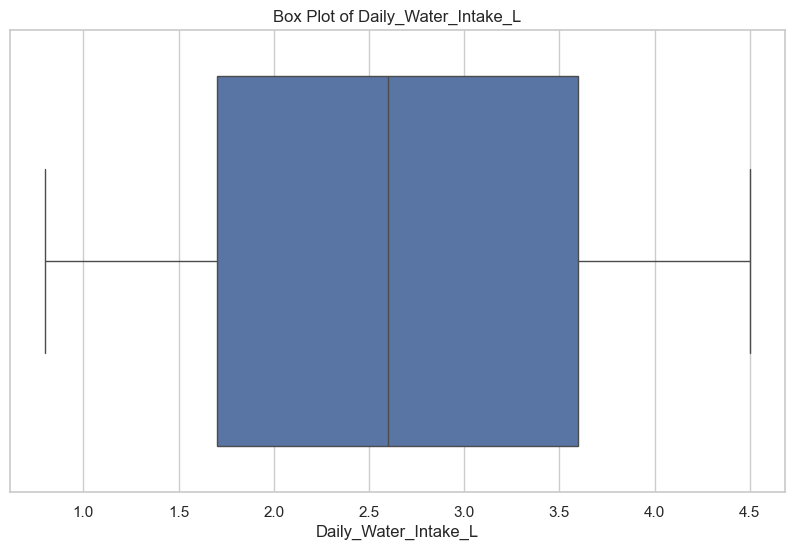

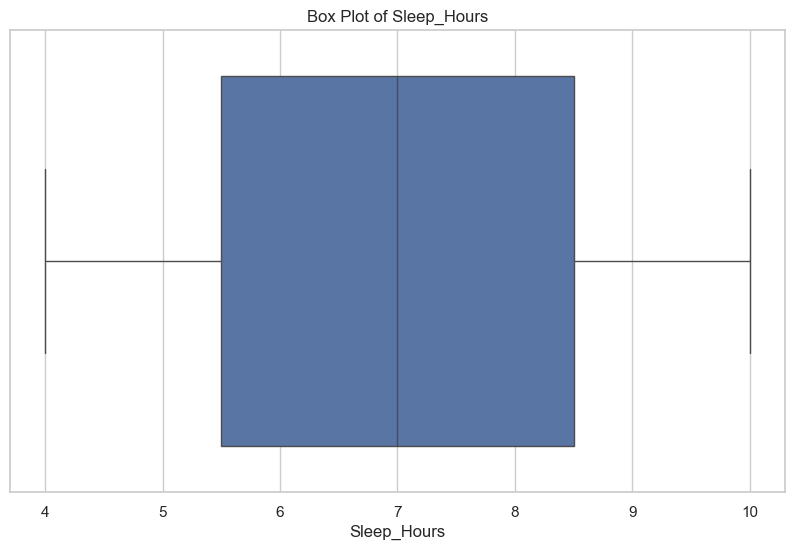

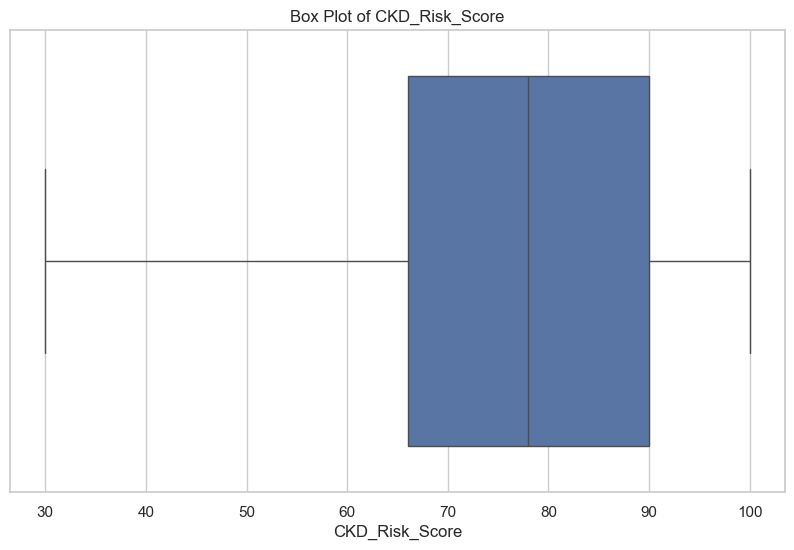

In [12]:
eda_numeric_features = df.select_dtypes(include=['number']).columns
for feature in eda_numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [13]:
# Identifikasi kolom numerik medis yang rawan outlier
cols_for_iqr = ['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Blood_Pressure_Systolic', 
                'Blood_Pressure_Diastolic', 'Blood_Glucose', 'Serum_Creatinine', 
                'Blood_Urea', 'eGFR', 'Albumin', 'Hemoglobin']

# Hitung Q1, Q3, dan IQR
Q1 = df_clean[cols_for_iqr].quantile(0.25)
Q3 = df_clean[cols_for_iqr].quantile(0.75)
IQR = Q3 - Q1

# Filter baris yang Tidak mengandung outlier
condition = ~((df_clean[cols_for_iqr] < (Q1 - 1.5 * IQR)) | (df_clean[cols_for_iqr] > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df_clean.loc[condition].reset_index(drop=True)

print(f"Jumlah data setelah dibersihkan dari outlier: {df_clean.shape[0]} baris")

Jumlah data setelah dibersihkan dari outlier: 49908 baris


In [14]:
# 1. SPLITTING
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. IMPUTASI
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['str']).columns

imputer_num = SimpleImputer(strategy='median')
X_train[num_cols] = imputer_num.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer_num.transform(X_test[num_cols])

imputer_cat = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = imputer_cat.fit_transform(X_train[cat_cols])
X_test[cat_cols] = imputer_cat.transform(X_test[cat_cols])

# 3. ENCODING (One-Hot)
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Sinkronisasi kolom
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

# 4. SCALING
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)
X_test_scaled = scaler.transform(X_test_enc)

In [15]:
initial_rows = df.shape[0]
df = df.dropna(subset=['CKD_Risk'])
print(f"Baris dibuang karena target kosong: {initial_rows - df.shape[0]}")
print(f"Sisa data bersih untuk di-split: {df.shape[0]} baris\n")

Baris dibuang karena target kosong: 0
Sisa data bersih untuk di-split: 49776 baris



In [16]:
# Imputasi Missing Values (Anti-Data Leakage)
# Numerik diisi dengan Median, Kategorik diisi dengan Modus
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['str']).columns

imputer_num = SimpleImputer(strategy='median')
X_train[num_cols] = imputer_num.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer_num.transform(X_test[num_cols])

imputer_cat = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = imputer_cat.fit_transform(X_train[cat_cols])
X_test[cat_cols] = imputer_cat.transform(X_test[cat_cols])

In [17]:
# Encoding Target & Fitur (One-Hot Encoding)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

In [18]:
# Standardisasi Data (Scaling)
scaler = StandardScaler()

# Fit HANYA di X_train, Transform di X_train dan X_test
X_train_scaled = scaler.fit_transform(X_train_enc)
X_test_scaled = scaler.transform(X_test_enc)

In [19]:
# Mapping Target & Identifikasi Fitur
risk_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
y_train_enc = y_train.map(risk_mapping)
y_test_enc = y_test.map(risk_mapping)

cat_cols = X_train.select_dtypes(include=['str', 'category']).columns
num_cols = X_train.select_dtypes(include=['number']).columns

print(f"Kolom Kategorikal yang akan di-encoding: {len(cat_cols)} kolom")
print(f"Kolom Numerik yang akan di-scaling: {len(num_cols)} kolom\n")

Kolom Kategorikal yang akan di-encoding: 17 kolom
Kolom Numerik yang akan di-scaling: 18 kolom



In [20]:
# One-Hot Encoding & Sinkronisasi Kolom
X_train_dummies = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_dummies = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

X_train_enc, X_test_enc = X_train_dummies.align(X_test_dummies, join='left', axis=1, fill_value=0)

print(f"Jumlah total fitur setelah One-Hot Encoding: {X_train_enc.shape[1]} kolom")

Jumlah total fitur setelah One-Hot Encoding: 70 kolom


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_enc)
X_test_scaled = scaler.transform(X_test_enc)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_enc.columns, index=X_train_enc.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test_enc.columns, index=X_test_enc.index)

print(f"Bentuk data Training setelah scaling: {X_train_scaled.shape}")
print(f"Bentuk data Testing setelah scaling: {X_test_scaled.shape}")

Bentuk data Training setelah scaling: (40000, 70)
Bentuk data Testing setelah scaling: (10000, 70)


In [22]:
# Inisialisasi Model dengan Regularisasi
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
    max_depth=12,
    min_samples_split=50,
    min_samples_leaf=20,
    max_features='sqrt'
)

# Melatih Model
model.fit(X_train_scaled, y_train_enc)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

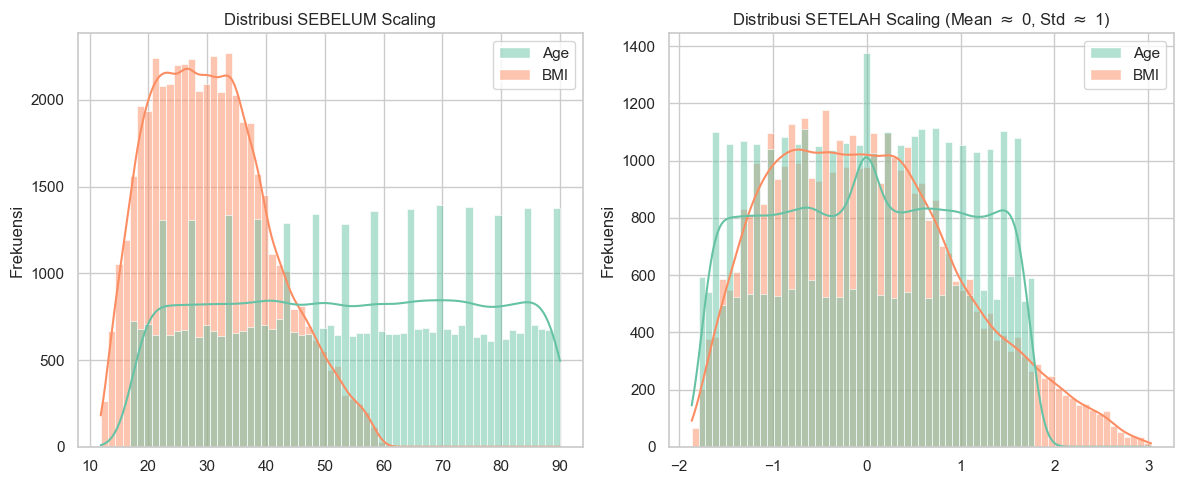

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

fitur_contoh = ['Age', 'BMI'] 

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Plot SEBELUM Scaling
sns.histplot(df_clean[fitur_contoh], kde=True, ax=axes[0], palette='Set2')
axes[0].set_title('Distribusi SEBELUM Scaling')
axes[0].set_ylabel('Frekuensi')

# 2. Plot SETELAH Scaling
sns.histplot(X_train_scaled[fitur_contoh], kde=True, ax=axes[1], palette='Set2')
axes[1].set_title(r'Distribusi SETELAH Scaling (Mean $\approx$ 0, Std $\approx$ 1)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [24]:
# prediksi pada data testing
y_test_pred = model.predict(X_test_scaled)

# prediksi data training untuk cek overfitting
y_train_pred = model.predict(X_train_scaled)

# B. Classification Report (Precision, Recall, F1-Score)
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']
print("\n--- CLASSIFICATION REPORT (DATA TESTING) ---")
print(classification_report(y_test_enc, y_test_pred, target_names=target_names, zero_division=0))


--- CLASSIFICATION REPORT (DATA TESTING) ---
              precision    recall  f1-score   support

     Low (0)       0.67      0.29      0.40        63
Moderate (1)       0.64      0.83      0.73      2172
    High (2)       0.95      0.88      0.91      7765

    accuracy                           0.86     10000
   macro avg       0.75      0.67      0.68     10000
weighted avg       0.88      0.86      0.87     10000



In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

def evaluasi_klasifikasi(nama_model, y_true, y_pred, labels=['Low', 'Moderate', 'High']):
    """Fungsi untuk mengevaluasi dan mencetak hasil model klasifikasi secara rapi"""
    
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    print(f"\n{'='*20} {nama_model} {'='*20}")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}\n")
    
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=labels, zero_division=0))
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(f'Confusion Matrix - {nama_model}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()
    
    # Mengembalikan nilai dalam bentuk list [Accuracy, Precision, Recall, F1-Score]
    return [acc, prec, rec, f1]

MODEL 1: RANDOM FOREST CLASSIFIER

==================== Random Forest Classifier ====================
Accuracy  : 0.8631
Precision : 0.7533
Recall    : 0.6652
F1-Score  : 0.6792

Classification Report:
              precision    recall  f1-score   support

         Low       0.67      0.29      0.40        63
    Moderate       0.64      0.83      0.73      2172
        High       0.95      0.88      0.91      7765

    accuracy                           0.86     10000
   macro avg       0.75      0.67      0.68     10000
weighted avg       0.88      0.86      0.87     10000



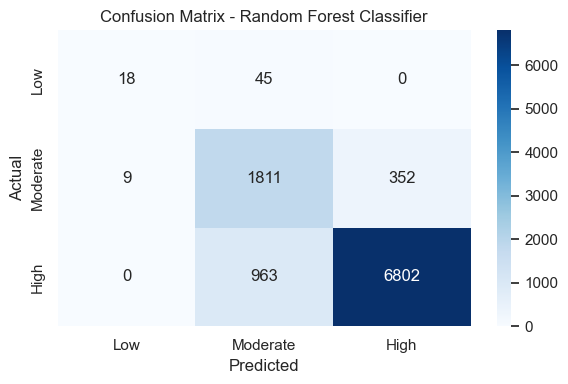

In [26]:
print("="*60)
print("MODEL 1: RANDOM FOREST CLASSIFIER")
print("="*60)

# Evaluasi
hasil_rf = evaluasi_klasifikasi("Random Forest Classifier", y_test_enc, y_test_pred)

MODEL 2: LOGISTIC REGRESSION

==================== Logistic Regression ====================
Accuracy  : 0.8965
Precision : 0.8002
Recall    : 0.6811
F1-Score  : 0.7253

Classification Report:
              precision    recall  f1-score   support

         Low       0.69      0.38      0.49        63
    Moderate       0.79      0.71      0.75      2172
        High       0.92      0.95      0.94      7765

    accuracy                           0.90     10000
   macro avg       0.80      0.68      0.73     10000
weighted avg       0.89      0.90      0.89     10000



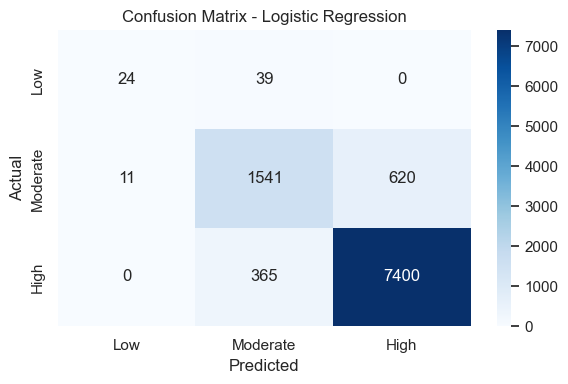

In [27]:
from sklearn.linear_model import LogisticRegression

print("="*60)
print("MODEL 2: LOGISTIC REGRESSION")
print("="*60)

# 1. Training
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train_enc)
y_test_pred_log = log_reg.predict(X_test_scaled)

# 2. Evaluasi
hasil_log = evaluasi_klasifikasi("Logistic Regression", y_test_enc, y_test_pred_log)

MODEL 3: HIST GRADIENT BOOSTING

==================== Hist Gradient Boosting ====================
Accuracy  : 0.9395
Precision : 0.7643
Recall    : 0.6553
F1-Score  : 0.6897

Classification Report:
              precision    recall  f1-score   support

         Low       0.44      0.17      0.25        63
    Moderate       0.90      0.81      0.85      2172
        High       0.95      0.98      0.97      7765

    accuracy                           0.94     10000
   macro avg       0.76      0.66      0.69     10000
weighted avg       0.94      0.94      0.94     10000



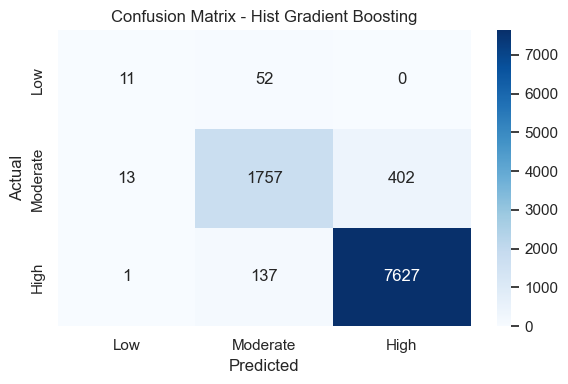

In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier

print("="*60)
print("MODEL 3: HIST GRADIENT BOOSTING")
print("="*60)

# 1. Training
hgb_clf = HistGradientBoostingClassifier(max_iter=100, random_state=42)
hgb_clf.fit(X_train_scaled, y_train_enc)
y_test_pred_hgb = hgb_clf.predict(X_test_scaled)

# 2. Evaluasi
hasil_hgb = evaluasi_klasifikasi("Hist Gradient Boosting", y_test_enc, y_test_pred_hgb)

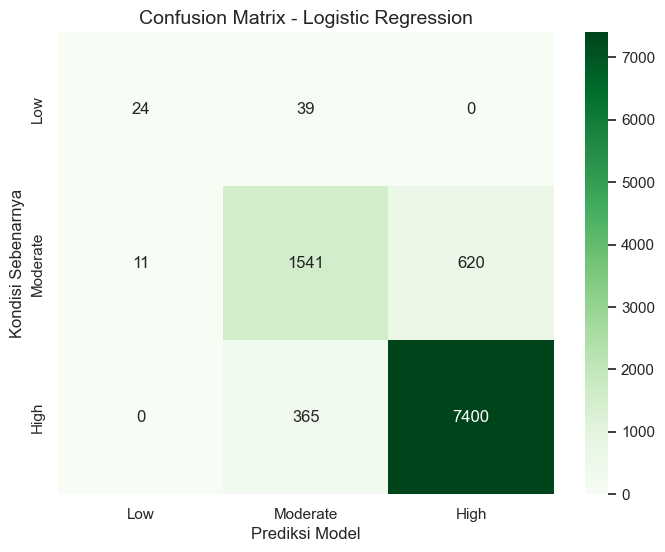

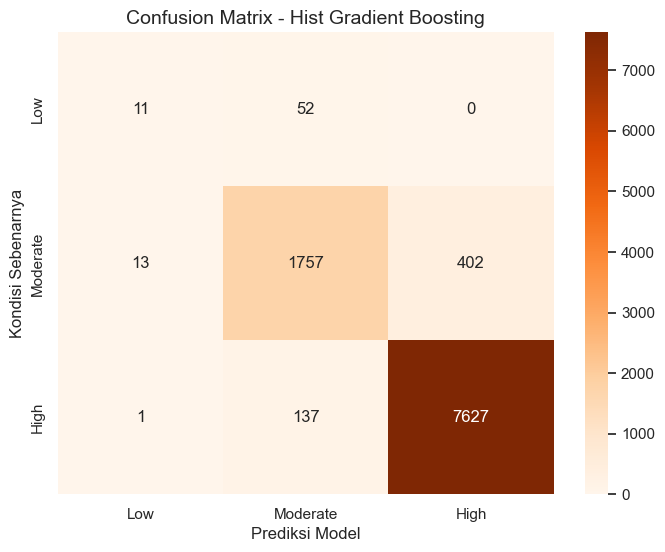

In [29]:
# 4. VISUALISASI CONFUSION MATRIX 
target_names = ['Low', 'Moderate', 'High']

# CM Logistic Regression
cm_log = confusion_matrix(y_test_enc, y_test_pred_log)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Logistic Regression', fontsize=14)
plt.xlabel('Prediksi Model', fontsize=12); plt.ylabel('Kondisi Sebenarnya', fontsize=12)
plt.show()

# CM Hist Gradient Boosting
cm_hgb = confusion_matrix(y_test_enc, y_test_pred_hgb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_hgb, annot=True, fmt='d', cmap='Oranges', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Hist Gradient Boosting', fontsize=14)
plt.xlabel('Prediksi Model', fontsize=12); plt.ylabel('Kondisi Sebenarnya', fontsize=12)
plt.show()

In [30]:
# ==============================================================================
# TABEL PERBANDINGAN: Model Klasifikasi
# ==============================================================================
print("="*65)
print("TABEL PERBANDINGAN PERFORMA MODEL KLASIFIKASI")
print("="*65)

comparison = pd.DataFrame({
    'Model': [
        'Random Forest Classifier', 
        'Logistic Regression', 
        'Hist Gradient Boosting'
    ],
    'Train Accuracy': [
        f"{accuracy_score(y_train_enc, y_train_pred):.4f}",
        f"{accuracy_score(y_train_enc, log_reg.predict(X_train_scaled)):.4f}",
        f"{accuracy_score(y_train_enc, hgb_clf.predict(X_train_scaled)):.4f}"
    ],
    'Test Accuracy': [
        f"{accuracy_score(y_test_enc, y_test_pred):.4f}",
        f"{accuracy_score(y_test_enc, y_test_pred_log):.4f}",
        f"{accuracy_score(y_test_enc, y_test_pred_hgb):.4f}"
    ],
    'Test F1-Score (Macro)': [
        f"{f1_score(y_test_enc, y_test_pred, average='macro', zero_division=0):.4f}",
        f"{f1_score(y_test_enc, y_test_pred_log, average='macro', zero_division=0):.4f}",
        f"{f1_score(y_test_enc, y_test_pred_hgb, average='macro', zero_division=0):.4f}"
    ],
    'Test Precision (Macro)': [
        f"{precision_score(y_test_enc, y_test_pred, average='macro', zero_division=0):.4f}",
        f"{precision_score(y_test_enc, y_test_pred_log, average='macro', zero_division=0):.4f}",
        f"{precision_score(y_test_enc, y_test_pred_hgb, average='macro', zero_division=0):.4f}"
    ],
    'Test Recall (Macro)': [
        f"{recall_score(y_test_enc, y_test_pred, average='macro', zero_division=0):.4f}",
        f"{recall_score(y_test_enc, y_test_pred_log, average='macro', zero_division=0):.4f}",
        f"{recall_score(y_test_enc, y_test_pred_hgb, average='macro', zero_division=0):.4f}"
    ]
})

display(comparison)

TABEL PERBANDINGAN PERFORMA MODEL KLASIFIKASI


,Model,Train Accuracy,Test Accuracy,Test F1-Score (Macro),Test Precision (Macro),Test Recall (Macro)
0,Random Forest Classifier,0.9094,0.8631,0.6792,0.7533,0.6652
1,Logistic Regression,0.8951,0.8965,0.7253,0.8002,0.6811
2,Hist Gradient Boosting,0.9792,0.9395,0.6897,0.7643,0.6553


,Accuracy,Precision,Recall,F1-Score
RF Classifier,0.8631,0.7533,0.6652,0.6792
Logistic Regression,0.8965,0.8002,0.6811,0.7253
Hist Gradient Boosting,0.9395,0.7643,0.6553,0.6897


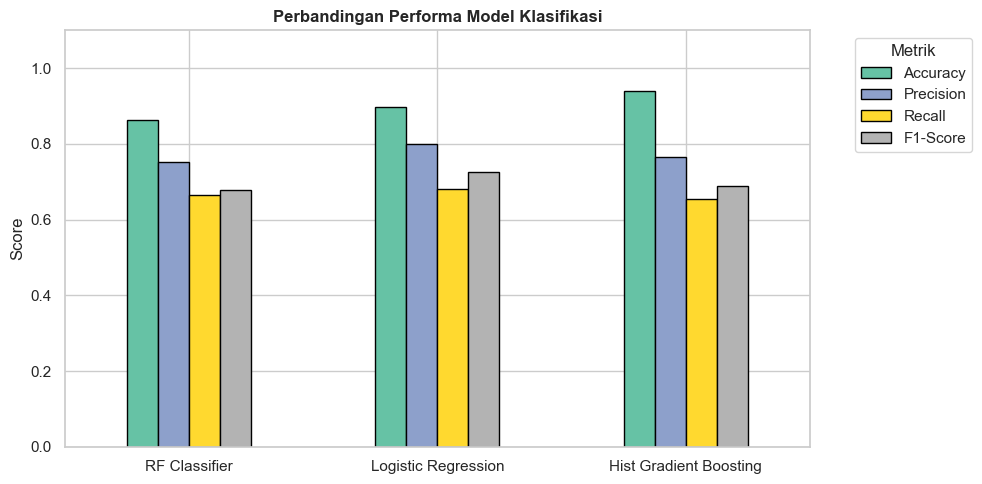

In [31]:
# 1. MEMBUAT TABEL PERBANDINGAN
perbandingan = pd.DataFrame(
    [hasil_rf, hasil_log, hasil_hgb],
    columns=['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    index=['RF Classifier', 'Logistic Regression', 'Hist Gradient Boosting']
)

display(perbandingan.round(4))

# 2. VISUALISASI BAR CHART PERBANDINGAN
fig, ax = plt.subplots(figsize=(10, 5))
perbandingan.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black')

ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Perbandingan Performa Model Klasifikasi', fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.legend(title='Metrik', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [32]:
# 1. Ekstrak nama fitur dan koefisien dari model Logistic Regression
feature_names = X_train_scaled.columns
coef = log_reg.coef_

# 2. Hitung rata-rata nilai absolut koefisien
mean_abs_coef = np.abs(coef).mean(axis=0)

# 3. Buat DataFrame dan urutkan dari yang paling besar
feature_imp = pd.DataFrame({'Feature': feature_names, 'Importance': mean_abs_coef})
feature_imp = feature_imp.sort_values(by='Importance', ascending=False)

# 4. Tampilkan Top 10 Fitur dalam bentuk tabel
print("\nTop 10 Fitur Paling Penting dalam Memprediksi Risiko CKD:")
display(feature_imp.head(10).reset_index(drop=True))


Top 10 Fitur Paling Penting dalam Memprediksi Risiko CKD:


,Feature,Importance
0,Serum_Creatinine,1.383531
1,eGFR,0.994649
2,Age,0.853148
3,Diabetes_Yes,0.695728
4,Blood_Urea,0.674121
5,Hypertension_Yes,0.669729
6,Family_History_CKD_Yes,0.612345
7,Blood_Pressure_Systolic,0.565876
8,Smoking_Status_Never,0.546529
9,Albumin,0.505336


In [33]:
import joblib

# Menyimpan semua model KLASIFIKASI yang sudah dilatih
joblib.dump(model, 'rf_classifier_ckd.joblib')         # Random Forest Classifier
joblib.dump(log_reg, 'logistic_regression_ckd.joblib') # Logistic Regression
joblib.dump(hgb_clf, 'hgb_classifier_ckd.joblib')      # Hist Gradient Boosting Classifier
joblib.dump(scaler, 'scaler_ckd.joblib')               # StandardScaler

['scaler_ckd.joblib']